# Telling Categories of Unexploded Ordnance Apart in Photos: a CNN Trained With and Without Hidden Patches

**Author:** Travis Carlson

**Dataset:** *CTX-UXO: A Comprehensive Dataset for Detection and Identification of UneXploded Ordnances* (Craioveanu & Stamatescu, 2025), Zenodo record [17052675](https://zenodo.org/records/17052675), CC BY 4.0

This notebook trains a convolutional neural network (CNN) in PyTorch to tell five categories of unexploded ordnance (UXO) apart in photos of real scenes, then trains it again with one change and compares the two. The photos come from CTX-UXO, a public dataset of 3,520 photos, mostly taken with phones, in which 15,449 objects are labelled with a box and one of 12 categories.

**Deep learning task type:** an image-based task with a convolutional neural network (CNN).

**Problem.** Supervised multi-class image classification with a CNN: given a 64 × 64 crop around one labelled object, predict its category among the five that make up 98% of the labels (projectile, grenade, mortar bomb, cartridge and aviation bomb). The intended use, drawn from the author's work as an explosive ordnance disposal (EOD) technician, is a first indication that a technician then confirms: photos from drones, survey teams or local people would reach a technician with the beginnings of an understanding, to be validated. The model never says that an object is safe, and an answer it is unsure of is passed on as "unknown".

**The experiment.** The baseline is a small CNN written in full in PyTorch. The second configuration changes exactly one thing: during training, part of each crop is hidden at random (random erasing; Zhong et al., 2020). Everything else stays the same, including the data, the architecture, the optimiser, the seeds and the order of the batches. The question is whether a model trained on partly hidden crops holds up better when part of an object is out of sight, since the features that tell items apart are often under brush or buried. Both models are tested on clear test crops and on the same crops with a patch hiding 10%, 25% and 40% of each, and the difference between them is given with a 95% interval from resampling the test photos.

**How the sections map to the brief.** Section 1 states the problem and the data (Task 1); section 2 loads and inspects it (Task 2); section 3 prepares the crops (Task 2 and 3); sections 4 and 5 define and train the baseline (Task 3); section 6 adds the second configuration (Task 4); section 7 evaluates and compares the two (Task 5); section 8 is the summary (Task 6).

**Data handling.** The notebook stays at the level of categories and counts: it shows the objects but gives no technical detail of how any of them work. The original 3.9 GB archive is not needed to run it: the crops it uses ship with the notebook, and section 3.1 rebuilds them from the archive when the archive is present.

*References cited in this notebook:*
- Craioveanu, G. M., & Stamatescu, G. (2025). *CTX-UXO: A comprehensive dataset for detection and identification of unexploded ordnances* (Version 1) [Data set]. Zenodo. https://zenodo.org/records/17052675
- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.
- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press. https://www.deeplearningbook.org
- Ioffe, S., & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. *Proceedings of the 32nd International Conference on Machine Learning, 37*, 448–456. https://proceedings.mlr.press/v37/ioffe15.html
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *3rd International Conference on Learning Representations*. https://arxiv.org/abs/1412.6980
- Lin, M., Chen, Q., & Yan, S. (2014). Network in network. *2nd International Conference on Learning Representations*. https://arxiv.org/abs/1312.4400
- Loshchilov, I., & Hutter, F. (2017). SGDR: Stochastic gradient descent with warm restarts. *5th International Conference on Learning Representations*. https://arxiv.org/abs/1608.03983
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., Killeen, T., Lin, Z., Gimelshein, N., Antiga, L., Desmaison, A., Köpf, A., Yang, E., DeVito, Z., Raison, M., Tejani, A., Chilamkurthy, S., Steiner, B., Fang, L., . . . Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*, 8024–8035. https://arxiv.org/abs/1912.01703
- Simonyan, K., & Zisserman, A. (2015). Very deep convolutional networks for large-scale image recognition. *3rd International Conference on Learning Representations*. https://arxiv.org/abs/1409.1556
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*(56), 1929–1958. https://jmlr.org/papers/v15/srivastava14a.html
- Zhong, Z., Zheng, L., Kang, G., Li, S., & Yang, Y. (2020). Random erasing data augmentation. *Proceedings of the AAAI Conference on Artificial Intelligence, 34*(07), 13001–13008. https://doi.org/10.1609/aaai.v34i07.7000

## 1. Problem and data

### 1.1 Setup

Libraries, file locations and checksums, fixed settings, and the chart style of the earlier projects. The workflow uses Python, NumPy, Pandas, Matplotlib, Seaborn, Pillow and PyTorch.

Every random step is seeded, PyTorch is told to use deterministic algorithms, and training runs on the CPU with a fixed number of threads. A GPU would be faster, but its results can differ slightly from run to run; on the CPU, rerunning the notebook on the same computer gives the same numbers. A different processor may round some sums in a different order, and over thousands of training steps such tiny differences can grow, so on another computer the scores can differ somewhat from those shown here (section 7.4 shows how far such differences moved the results between two runs on this computer).

In [1]:
import copy
import csv
import hashlib
import io
import json
import math
import time
import zipfile
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns
import PIL
from PIL import Image
import torch
import torch.nn as nn

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# Files (the data folder sits next to this notebook)
DATA_DIR = Path("data")
CROPS_ZIP = DATA_DIR / "ctx_uxo_crops_64.zip"      # one 64 x 64 JPEG crop per labelled object
CROPS_CSV = DATA_DIR / "crops_manifest.csv"        # one row per crop: split, category, source photo, box
PHOTOS_CSV = DATA_DIR / "photos_manifest.csv"      # one row per photo: split, size, objects, image hash
SAMPLE_DIR = DATA_DIR / "sample_photos"            # six photos, shrunk, to show the scenes
ARCHIVE = DATA_DIR / "CTX_UXO_DS_v2_2025.zip"      # optional: the original archive, to rebuild the crops
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Provenance of the data
RECORD_PAGE = "https://zenodo.org/records/17052675"
ARCHIVE_URL = "https://zenodo.org/records/17052675/files/CTX_UXO_DS_v2_2025.zip?download=1"
ARCHIVE_MD5 = "4191257476e65a50f72dfb9d3ad3213d"   # as listed on the record
DOWNLOADED_ON = "2026-10-20"
EXPECTED_SHA256 = {
    "ctx_uxo_crops_64.zip": "9f3cbc88609089864fba9b418c39ec8eb9a97a2451ffdddb2116b1a1695c87c1",
    "crops_manifest.csv": "4a4322ff01b9390b14e5a7d416676cb1d6e457cf725e5e2ac10aba04f7e8c306",
    "photos_manifest.csv": "53c0c67e9b3d7e704735513f731ab9a437c803e3fd30871d21c385e730eee166",
}

# Fixed settings
SEED = 0                    # one seed for every random step
THREADS = 2                 # CPU threads used by PyTorch, fixed so results do not depend on the computer's core count
CATEGORIES = ["Projectile", "Grenade", "Mortar Bomb", "Cartridge", "Aviation Bomb"]  # the five kept, largest first
EPOCHS = 20                 # passes over the training crops for each model
BATCH = 64                  # crops per training step
LEARNING_RATE = 0.001       # Adam's starting step size, lowered along a cosine curve over the epochs
HIDDEN_SHARES = [0.10, 0.25, 0.40]  # share of each test crop hidden in the partly hidden tests
TARGET_ACCURACY = 0.95      # accuracy the "unknown" cut-off must reach on the validation crops it keeps

torch.manual_seed(SEED)
torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)

# Chart style: light surface, quiet grid, neutrals for the data and one fixed colour per model and category
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
MODEL_COLOURS = {"Baseline": "#2a78d6", "Random erasing": "#eb6834"}
CATEGORY_COLOURS = dict(zip(CATEGORIES, ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cd1", "#c9a227"]))

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "font.size": 10, "lines.linewidth": 2, "legend.frameon": False,
})


def save_fig(fig, name):
    """Save a figure to the figures folder at print resolution (JPEG for photos, PNG for charts) and return its path."""
    path = FIG_DIR / name
    options = {"pil_kwargs": {"quality": 90}} if path.suffix == ".jpg" else {}
    fig.savefig(path, dpi=200, bbox_inches="tight", **options)
    return path


for name, module in [("numpy", np), ("pandas", pd), ("matplotlib", matplotlib), ("seaborn", sns),
                     ("pillow", PIL), ("torch", torch)]:
    print(f"{name:<11} {module.__version__}")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"\nPyTorch device available: {device}; training runs on the CPU with {THREADS} threads.")

numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
seaborn     0.13.2
pillow      13.0.0
torch       2.14.1+cpu

PyTorch device available: cpu; training runs on the CPU with 2 threads.


### 1.2 The dataset

CTX-UXO was published by Gheorghe Marian Craioveanu and Grigore Stamatescu of the National University of Science and Technology Politehnica Bucharest, with logistical support from Romania's emergency services inspectorate, under a CC BY 4.0 licence. Its record describes it as "a collection of labeled UXO images in various visual contexts within the visible spectrum", taken "across multiple environments, angles, distances, and with various types of cameras", mostly mobile phones. It also notes that "replicas of munitions ... were used to diversify the dataset by relocating or arranging them in new positions and environments". The creators split the 3,520 photos into training, validation and test folders (70%, 15% and 15%), balancing the categories across the three.

It meets the brief's dataset rules: images suited to a CNN, enough labelled examples to train and evaluate, public and licensed for academic use, real photos rather than synthetic or generated ones, and not used in an earlier project.

Two points shaped the task:
- **No negatives.** Every label is a UXO category, and every photo holds at least one labelled object. The record's "binary (UXO/NON-UXO)" use means objects against background, not harmless look-alike objects, so the data cannot train a "UXO or not" model. The task is therefore to tell categories apart.
- **Two class names checked.** The record's text gives 4,269 mortar bombs and 3,399 grenades; the label files give the opposite. A blind check by a specialist (the author) of 12 crops from each class, shown without their names, confirmed the label files.

## 2. Load and inspect

### 2.1 Data files and checksums

The notebook reads three files made from the original archive (section 3.1 shows how): the crops, one row per crop, and one row per photo. Their SHA-256 checksums are compared with the values recorded when they were built, so anyone rerunning the notebook can confirm they use the same data. The original archive is optional; if it is present, its MD5 checksum is compared with the one on the record.

In [2]:
def file_digest(path, algorithm="sha256"):
    """Return the hex digest of a file, reading it in 1 MB chunks."""
    digest = hashlib.new(algorithm)
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print(f"Dataset record: {RECORD_PAGE} (downloaded on {DOWNLOADED_ON})\n")
for path in [CROPS_ZIP, CROPS_CSV, PHOTOS_CSV]:
    digest = file_digest(path)
    verdict = "matches the recorded value" if digest == EXPECTED_SHA256[path.name] else "WARNING: differs from the recorded value"
    print(f"{path.name:<22} {path.stat().st_size:>12,} bytes   SHA-256 {digest[:12]}...  {verdict}")

if ARCHIVE.exists():
    md5 = file_digest(ARCHIVE, "md5")
    print(f"\nOriginal archive found: MD5 {md5}", "matches the record." if md5 == ARCHIVE_MD5 else "WARNING: differs from the record.")
else:
    print(f"\nThe original archive is not in {DATA_DIR}/ (it is optional, 3.9 GB, from {ARCHIVE_URL}).")

Dataset record: https://zenodo.org/records/17052675 (downloaded on 2026-10-20)

ctx_uxo_crops_64.zip     52,425,863 bytes   SHA-256 9f3cbc886090...  matches the recorded value
crops_manifest.csv        1,236,528 bytes   SHA-256 4a4322ff01b9...  matches the recorded value
photos_manifest.csv         215,881 bytes   SHA-256 53c0c67e9b3d...  matches the recorded value

The original archive is not in data/ (it is optional, 3.9 GB, from https://zenodo.org/records/17052675/files/CTX_UXO_DS_v2_2025.zip?download=1).


### 2.2 The photos

One row per photo: its split, its size in pixels, the size the labels refer to, its EXIF orientation tag (a tag that tells viewers to rotate the image), how many objects are labelled in it, and a 64-bit image hash used in section 2.4.

In [3]:
photos = pd.read_csv(PHOTOS_CSV, dtype={"dhash": str})
crops = pd.read_csv(CROPS_CSV)
print(f"{len(photos):,} photos and {len(crops):,} labelled objects\n")
print(photos.head(3).to_string(index=False), "\n")
print(photos.dtypes.to_string(), "\n")

by_split = photos.groupby("split", sort=False).agg(photos=("photo", "size"), objects=("objects", "sum"),
                                                   median_objects=("objects", "median"), max_objects=("objects", "max"))
print(by_split.to_string(), "\n")
same_size = ((photos.width == photos.label_width) & (photos.height == photos.label_height)).all()
print("Every photo has the size its labels refer to:", same_size)
print("EXIF orientation tags:", photos.exif_orientation.value_counts().to_dict(), "(1 = upright as stored)")
sizes = photos.apply(lambda r: f"{r.width} x {r.height}", axis=1).value_counts()
print(f"\n{sizes.size} different photo sizes; the five most common:")
print(sizes.head(5).to_string())

3,520 photos and 15,449 labelled objects

split        photo  width  height  label_width  label_height  exif_orientation  objects            dhash
train   UXOs_1.jpg    640     480          640           480                 1        1 9935ba476fc46894
train  UXOs_10.jpg   1500    2000         1500          2000                 1        1 4b4dbb5236647d3c
train UXOs_100.jpg   1530    2040         1530          2040                 1        4 4b26646464676706 

split                 str
photo                 str
width               int64
height              int64
label_width         int64
label_height        int64
exif_orientation    int64
objects             int64
dhash                 str 

       photos  objects  median_objects  max_objects
split                                              
train    2461    11146             1.0          325
valid     530     1862             1.0          141
test      529     2441             1.0          263 

Every photo has the size its labels re

Six photos from the training split, shrunk for display, with their labelled boxes: one for each of the five categories kept, and one with many objects.

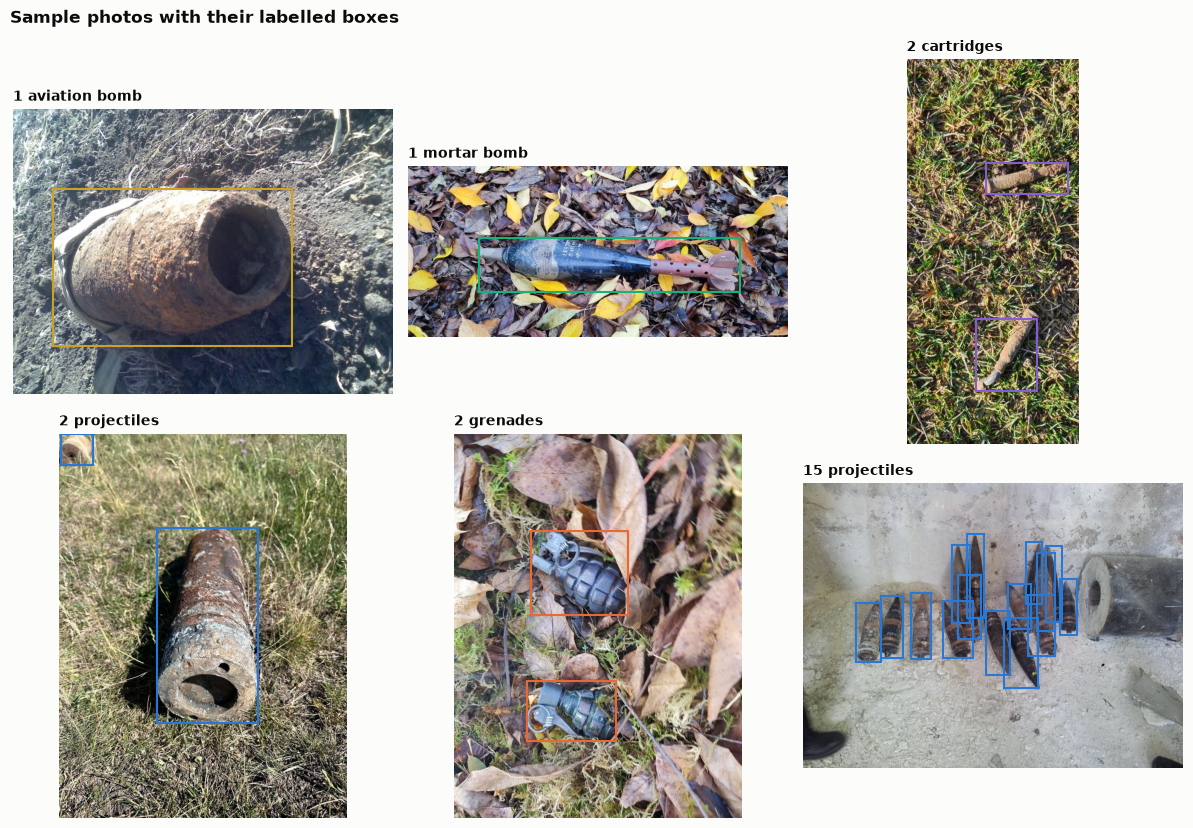

In [4]:
sample_files = sorted(SAMPLE_DIR.glob("*.jpg"), key=lambda p: (photos.set_index("photo").loc[p.name, "objects"], p.name))
fig, axes = plt.subplots(2, 3, figsize=(12, 8.4))
for ax, path in zip(axes.flat, sample_files):
    image = Image.open(path)
    info = photos.set_index("photo").loc[path.name]
    scale = image.width / info.width
    ax.imshow(image)
    for box in crops[crops.photo == path.name].itertuples():
        colour = CATEGORY_COLOURS.get(box.category, INK)
        ax.add_patch(Rectangle((box.box_x * scale, box.box_y * scale), box.box_w * scale, box.box_h * scale,
                               fill=False, edgecolor=colour, linewidth=1.5))
    names = crops[crops.photo == path.name].category.value_counts()
    ax.set_title(", ".join(f"{n} {c.lower()}{'s' if n > 1 else ''}" for c, n in names.items()), fontsize=10)
    ax.axis("off")
fig.suptitle("Sample photos with their labelled boxes", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "01_sample_photos.jpg")
plt.show()

### 2.3 The labels

Labelled objects by category and split. Five categories hold 98% of the labels; the other seven have between 5 and 124 objects each, too few to learn or test. They are kept apart for one check in section 7.8: what the models say about objects of a kind they never saw.

In [5]:
counts = crops.pivot_table(index="category", columns="split", values="crop_id", aggfunc="count", fill_value=0)
counts = counts[["train", "valid", "test"]]
counts["total"] = counts.sum(axis=1)
counts["share"] = (counts.total / counts.total.sum()).map("{:.1%}".format)
counts = counts.sort_values("total", ascending=False)
counts["kept"] = np.where(counts.index.isin(CATEGORIES), "yes", "no")
print(counts.to_string(), "\n")
kept = counts.loc[CATEGORIES, "total"].sum()
print(f"Five categories kept: {kept:,} of {len(crops):,} objects ({kept / len(crops):.1%}); "
      f"left out: {len(crops) - kept:,}.")
print(f"Largest to smallest kept category: {counts.loc['Projectile', 'total'] / counts.loc['Aviation Bomb', 'total']:.1f} to 1.")

split               train  valid  test  total  share kept
category                                                 
Projectile           4465    672   984   6121  39.6%  yes
Grenade              3105    514   650   4269  27.6%  yes
Mortar Bomb          2387    453   559   3399  22.0%  yes
Cartridge             738    100   149    987   6.4%  yes
Aviation Bomb         224     44    65    333   2.2%  yes
Cartridge Magazine     99     23     2    124   0.8%   no
Fuse                   40     38    14     92   0.6%   no
RPG                    44      8    11     63   0.4%   no
LandMine               25      3     1     29   0.2%   no
Rocket                 12      5     4     21   0.1%   no
AntiSubmarine Bomb      4      1     1      6   0.0%   no
Sea Mine                3      1     1      5   0.0%   no 

Five categories kept: 15,109 of 15,449 objects (97.8%); left out: 340.
Largest to smallest kept category: 18.4 to 1.


### 2.4 Data quality

Four checks on the photos and boxes:
- **Near-duplicate photos.** Each photo's 64-bit difference hash records whether each pixel of a 9 × 8 grey thumbnail is brighter than its neighbour, so near-identical photos get hashes that differ in few bits. Pairs within 4 bits of each other are counted within and across the splits; a test photo with a near-duplicate in the training or validation split would make the test easier than a new photo.
- **Crops per photo.** Many photos hold one object, but some hold piles of dozens or hundreds. Crops from one photo share its scene, light and camera, so they are not independent examples, and a few large photos can carry much of a split.
- **Object size.** The share of the photo each box covers.
- **Crops at the edge.** Crops whose square runs past the edge of the photo, where the missing part is filled with grey.

In [6]:
hashes = np.array([int(h, 16) for h in photos.dhash], dtype=np.uint64)
distance = np.bitwise_count(hashes[:, None] ^ hashes[None, :])  # bits that differ, for every pair of photos
first, second = np.nonzero(np.triu(distance <= 4, k=1))         # each pair within 4 bits, once
split_of = photos.split.to_numpy()
identical = distance[first, second] == 0
pair_kind = pd.Series([" / ".join(sorted(pair)) for pair in zip(split_of[first], split_of[second])])
print(f"Photo pairs within 4 bits of each other: {len(first)} ({identical.sum()} with identical hashes)")
print(pair_kind.value_counts().to_string(), "\n")

# Test photos with a near-duplicate in the training or validation split (used again in section 7.5)
near_duplicate = np.zeros(len(photos), dtype=bool)
for a, b in zip(first, second):
    if {split_of[a], split_of[b]} in ({"test", "train"}, {"test", "valid"}):
        near_duplicate[a if split_of[a] == "test" else b] = True
leaky_photos = set(photos.photo[near_duplicate])
kept_crops = crops[crops.category.isin(CATEGORIES)]
test_crops = kept_crops[kept_crops.split == "test"]
print(f"Test photos with a near-duplicate in training or validation: {len(leaky_photos)} of {(photos.split == 'test').sum()}, "
      f"holding {test_crops.photo.isin(leaky_photos).sum()} of the {len(test_crops):,} test crops kept.")
objects = photos.objects.to_numpy()
print(f"Identical-hash pairs whose label counts differ: {(objects[first[identical]] != objects[second[identical]]).sum()} "
      f"of {identical.sum()}\n")

print("Crops of the five categories kept, by photo:")
for split in ["train", "valid", "test"]:
    per_photo = kept_crops[kept_crops.split == split].photo.value_counts()
    print(f"  {split:<6} {per_photo.sum():>6,} crops from {per_photo.size:>5,} photos; median {per_photo.median():.0f} per photo, "
          f"largest {per_photo.iloc[0]}; the 10 largest photos hold {per_photo.head(10).sum() / per_photo.sum():.0%}")
concentration = {}
for split in ["train", "valid", "test"]:
    n_photos, top_share = {}, {}
    for category in CATEGORIES:
        per_photo = kept_crops[(kept_crops.split == split) & (kept_crops.category == category)].photo.value_counts()
        n_photos[category] = per_photo.size
        top_share[category] = f"{per_photo.head(3).sum() / per_photo.sum():.0%}"
    concentration[(split, "photos")] = n_photos
    concentration[(split, "in largest 3")] = top_share
print("\nPhotos per category, and the share of the category's crops in its 3 largest photos:")
print(pd.DataFrame(concentration).to_string(), "\n")

area = crops.merge(photos[["photo", "width", "height"]], on="photo")
share = area.box_w * area.box_h / (area.width * area.height)
print("Share of the photo covered by a box:", " | ".join(f"{q:.0%} quantile {share.quantile(q):.2%}" for q in (0.1, 0.5, 0.9)))
print(f"Crops that run past the edge of their photo (grey fill): {crops.padded.sum():,} of {len(crops):,} ({crops.padded.mean():.1%})")

Photo pairs within 4 bits of each other: 123 (99 with identical hashes)
train / train    53
train / valid    33
test / train     27
test / valid      5
valid / valid     4
test / test       1 

Test photos with a near-duplicate in training or validation: 31 of 529, holding 57 of the 2,407 test crops kept.
Identical-hash pairs whose label counts differ: 6 of 99

Crops of the five categories kept, by photo:
  train  10,919 crops from 2,426 photos; median 1 per photo, largest 325; the 10 largest photos hold 15%
  valid   1,783 crops from   517 photos; median 1 per photo, largest 141; the 10 largest photos hold 31%
  test    2,407 crops from   522 photos; median 1 per photo, largest 263; the 10 largest photos hold 39%

Photos per category, and the share of the category's crops in its 3 largest photos:
               train               valid                test             
              photos in largest 3 photos in largest 3 photos in largest 3
Projectile      1030          14%    221   

**What the checks show.** All 3,520 photos are stored upright (EXIF orientation 1) and have the size their labels refer to, so the boxes are used as given. Of the 123 pairs of photos within 4 bits of each other, 99 have identical hashes. Most pairs lie within the training split or between training and validation, but 31 test photos have a near-duplicate in the training or validation split; they hold 57 of the 2,407 test crops, and section 7.5 scores the models without them. In 6 of the 99 identical pairs the two copies carry different numbers of labels, so some objects were labelled in one copy and not in the other.

Crops cluster in a few photos. The median photo holds one crop, but the 10 largest test photos hold 39% of the test crops, and the 149 test cartridges come from only 6 photos, 3 of which hold 88% of them. Test scores therefore rest on fewer independent scenes than the crop counts suggest, above all for cartridges, and section 7.4 puts intervals on them. Half of the boxes cover less than 1.04% of their photo and a tenth less than 0.11%, and almost a quarter of the crops (23.6%) run past the edge of their photo and carry a grey band.

## 3. Prepare the crops

### 3.1 Build the crops from the archive

Each labelled object is cut out as a square around its box, widened by 15% of the box's longer side on each side to keep some context, filled with grey where the square runs past the edge of the photo, and shrunk to 64 × 64 pixels. The size of 64 pixels was set by a timing test, to keep a training epoch of this CNN under a minute on a 2-core processor. Large photos are decoded at a reduced scale when even the smallest crop in them keeps at least twice the output size, which is faster and changes nothing at 64 pixels. The crops are saved as high-quality JPEGs in one zip file, with fixed timestamps so that rebuilding gives a byte-identical file.

The code below made the shipped files. It runs only when the original archive sits in the data folder; otherwise the notebook goes on with the shipped crops.

In [7]:
CROP_SIZE = 64              # pixels per side of each saved crop
MARGIN = 0.15               # extra context on each side, as a share of the object's longer side
PAD_GREY = (128, 128, 128)  # fills any part of a crop that falls outside the photo
SPLITS = [("train", "coco_train"), ("valid", "coco_val"), ("test", "coco_test")]
FIXED_TIME = (2026, 1, 1, 0, 0, 0)  # zip entry timestamp, so a rebuild is byte-identical


def difference_hash(photo):
    """Return a 64-bit difference hash of a photo as 16 hex digits.

    The photo is shrunk to 9 x 8 grey pixels and each bit records whether a pixel is brighter
    than its right-hand neighbour. Near-identical photos get hashes that differ in only a few bits.
    """
    small = photo.convert("L").resize((9, 8), Image.Resampling.LANCZOS)
    pixels = list(small.tobytes())  # one byte per pixel in mode "L"
    bits = 0
    for row in range(8):
        for col in range(8):
            bits = (bits << 1) | int(pixels[row * 9 + col] > pixels[row * 9 + col + 1])
    return f"{bits:016x}"


def build_crops(archive, out_dir, size=CROP_SIZE, margin=MARGIN):
    """Write the crops zip, the crop manifest and the photo manifest into `out_dir`.

    Each labelled object becomes one JPEG crop: a square around its box, widened by `margin` on
    each side, padded with grey where it runs off the photo, and resized to `size` pixels.
    Returns the number of crops and photos.
    """
    out_dir = Path(out_dir)
    crop_rows, photo_rows = [], []
    with zipfile.ZipFile(archive) as source, \
            zipfile.ZipFile(out_dir / "ctx_uxo_crops_64.zip", "w", zipfile.ZIP_STORED) as out:
        for split, coco_name in SPLITS:
            coco = json.loads(source.read(f"coco_labels/{coco_name}.json"))
            names = {c["id"]: c["name"] for c in coco["categories"]}
            images = {im["id"]: im for im in coco["images"]}
            by_image = defaultdict(list)
            for ann in coco["annotations"]:
                by_image[ann["image_id"]].append(ann)
            for image_id in sorted(images):
                info = images[image_id]
                width, height = info["width"], info["height"]
                anns = sorted(by_image[image_id], key=lambda a: a["id"])
                sides = [max(a["bbox"][2], a["bbox"][3]) * (1 + 2 * margin) for a in anns]
                # Decode the JPEG at reduced scale when even the smallest crop keeps at least twice the output size.
                scale = 1
                while sides and scale < 8 and min(sides) / (scale * 2) >= 2 * size:
                    scale *= 2
                with source.open(f"images/{split}/images/{info['file_name']}") as handle:
                    photo = Image.open(io.BytesIO(handle.read()))
                    orientation = photo.getexif().get(0x0112, 1)
                    stored_size = photo.size
                    if scale > 1:
                        photo.draft("RGB", (width // scale, height // scale))
                    photo = photo.convert("RGB")
                photo_rows.append({"split": split, "photo": info["file_name"], "width": stored_size[0],
                                   "height": stored_size[1], "label_width": width, "label_height": height,
                                   "exif_orientation": orientation, "objects": len(anns),
                                   "dhash": difference_hash(photo)})
                sx, sy = photo.width / width, photo.height / height
                for ann, side in zip(anns, sides):
                    x, y, w, h = ann["bbox"]
                    cx, cy = x + w / 2, y + h / 2
                    left, top = (cx - side / 2) * sx, (cy - side / 2) * sy
                    right, bottom = (cx + side / 2) * sx, (cy + side / 2) * sy
                    canvas = Image.new("RGB", (round(right - left), round(bottom - top)), PAD_GREY)
                    box = (max(0, round(left)), max(0, round(top)),
                           min(photo.width, round(right)), min(photo.height, round(bottom)))
                    canvas.paste(photo.crop(box), (box[0] - round(left), box[1] - round(top)))
                    crop = canvas.resize((size, size), Image.Resampling.LANCZOS)
                    crop_id = len(crop_rows)
                    name = f"{split}/{crop_id:05d}.jpg"
                    buffer = io.BytesIO()
                    crop.save(buffer, "JPEG", quality=95)
                    out.writestr(zipfile.ZipInfo(name, date_time=FIXED_TIME), buffer.getvalue())
                    crop_rows.append({"crop_id": crop_id, "crop_file": name, "split": split,
                                      "category_id": ann["category_id"], "category": names[ann["category_id"]],
                                      "photo": info["file_name"], "box_x": round(x, 1), "box_y": round(y, 1),
                                      "box_w": round(w, 1), "box_h": round(h, 1),
                                      "padded": int(left < 0 or top < 0 or right > photo.width or bottom > photo.height)})
    for rows, name in [(crop_rows, "crops_manifest.csv"), (photo_rows, "photos_manifest.csv")]:
        with open(out_dir / name, "w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)
    return len(crop_rows), len(photo_rows)


if ARCHIVE.exists():
    rebuilt = Path("rebuilt_crops")
    rebuilt.mkdir(exist_ok=True)
    started = time.perf_counter()
    n_crops, n_photos = build_crops(ARCHIVE, rebuilt)
    print(f"Rebuilt {n_crops:,} crops from {n_photos:,} photos in {time.perf_counter() - started:.0f} s")
    for name, expected in EXPECTED_SHA256.items():
        same = file_digest(rebuilt / name) == expected
        print(f"{name:<22} {'identical to the shipped file' if same else 'WARNING: differs from the shipped file'}")
else:
    print("The original archive is not present, so the shipped crops are used. To rebuild them, download "
          f"{ARCHIVE_URL} into {DATA_DIR}/ and run this cell again.")

The original archive is not present, so the shipped crops are used. To rebuild them, download https://zenodo.org/records/17052675/files/CTX_UXO_DS_v2_2025.zip?download=1 into data/ and run this cell again.


### 3.2 Load the crops

All 15,449 crops are read into one array of 8-bit RGB pixels, in the order of the crop manifest.

In [8]:
def load_crops(zip_path, names):
    """Read JPEG crops from a zip file into an array of shape (crops, height, width, 3), 8-bit RGB."""
    with zipfile.ZipFile(zip_path) as archive:
        return np.stack([np.asarray(Image.open(io.BytesIO(archive.read(name))).convert("RGB")) for name in names])


images = load_crops(CROPS_ZIP, crops.crop_file)
print(f"Crops: {images.shape} {images.dtype}, values {images.min()} to {images.max()}")

Crops: (15449, 64, 64, 3) uint8, values 0 to 255


Eight training crops from each of the five categories kept.

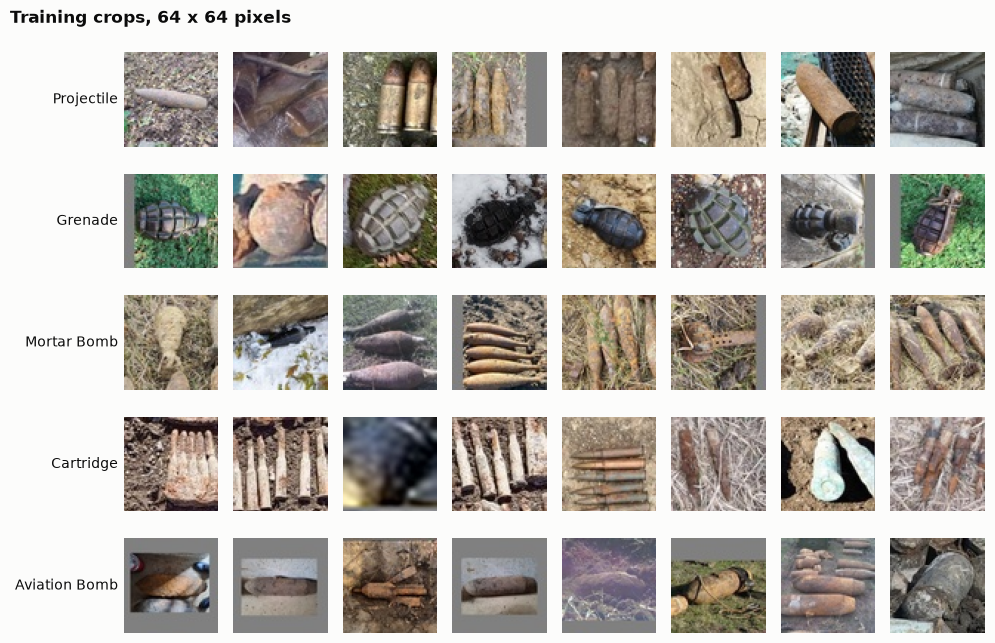

In [9]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(CATEGORIES), 8, figsize=(10, 6.6))
for row, category in enumerate(CATEGORIES):
    pool = np.flatnonzero(((crops.category == category) & (crops.split == "train")).to_numpy())
    for col, index in enumerate(rng.choice(pool, 8, replace=False)):
        ax = axes[row, col]
        ax.imshow(images[index])
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[row, 0].set_ylabel(category, rotation=0, ha="right", va="center", fontsize=10, color=INK)
fig.suptitle("Training crops, 64 x 64 pixels", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_sample_crops.jpg")
plt.show()

### 3.3 Model inputs

The five categories are numbered 0 to 4 in order of size. The creators' splits are kept, so all crops from one photo stay in one split. Pixel values are scaled to 0–1 and then standardised per colour channel with the mean and standard deviation of the training crops, so the network starts from inputs of similar range; validation and test crops use the same values.

Because projectiles outnumber aviation bombs about 18 to 1, the loss weights each category by the inverse of its share of the training crops, so that every category counts equally in total, the weighting scikit-learn calls "balanced".

In [10]:
main = crops.category.isin(CATEGORIES).to_numpy()
labels = crops.category.map({c: i for i, c in enumerate(CATEGORIES)}).fillna(-1).astype(int).to_numpy()
rows = {split: np.flatnonzero(main & (crops.split == split).to_numpy()) for split in ["train", "valid", "test"]}
unseen_rows = np.flatnonzero(~main)

train_unit = torch.from_numpy(images[rows["train"]]).permute(0, 3, 1, 2).float().div(255)
channel_mean = train_unit.mean(dim=(0, 2, 3))
channel_std = train_unit.std(dim=(0, 2, 3), correction=0)
del train_unit  # free the memory


def to_tensor(index):
    """Return crops as a float tensor of shape (crops, 3, 64, 64), standardised with the training statistics.

    The values are stored channel-last in memory, the order of the image files, which PyTorch's CPU
    convolutions process faster; the shape and the values are the same either way.
    """
    x = torch.from_numpy(images[index]).permute(0, 3, 1, 2).float().contiguous(memory_format=torch.channels_last)
    return x.div_(255).sub_(channel_mean[:, None, None]).div_(channel_std[:, None, None])


X = {split: to_tensor(index) for split, index in rows.items()}
Y = {split: torch.from_numpy(labels[index]) for split, index in rows.items()}
X_unseen = to_tensor(unseen_rows)

train_counts = torch.bincount(Y["train"], minlength=len(CATEGORIES)).float()
class_weights = train_counts.sum() / (len(CATEGORIES) * train_counts)

table = pd.DataFrame({split: np.bincount(Y[split].numpy(), minlength=len(CATEGORIES)) for split in Y}, index=CATEGORIES)
table["loss weight"] = class_weights.numpy().round(2)
print(table.to_string(), "\n")
for split in X:
    print(f"{split:<6} inputs {tuple(X[split].shape)} {X[split].dtype}, labels {tuple(Y[split].shape)} {Y[split].dtype}")
print(f"left-out categories: {len(unseen_rows)} crops")
print("channel mean (R, G, B):", channel_mean.numpy().round(3), " standard deviation:", channel_std.numpy().round(3))

               train  valid  test  loss weight
Projectile      4465    672   984         0.49
Grenade         3105    514   650         0.70
Mortar Bomb     2387    453   559         0.91
Cartridge        738    100   149         2.96
Aviation Bomb    224     44    65         9.75 

train  inputs (10919, 3, 64, 64) torch.float32, labels (10919,) torch.int64
valid  inputs (1783, 3, 64, 64) torch.float32, labels (1783,) torch.int64
test   inputs (2407, 3, 64, 64) torch.float32, labels (2407,) torch.int64
left-out categories: 340 crops
channel mean (R, G, B): [0.532 0.494 0.455]  standard deviation: [0.212 0.202 0.198]


### 3.4 Partly hidden test crops

For the comparison, each test crop is copied three times with one square patch hiding 10%, 25% or 40% of it (sides of 20, 32 and 40 pixels). The patch takes the training crops' average colour, which is 0 after standardisation, and its position is random but fixed by the seed, so both models see exactly the same patches. A patch of one flat colour is a simple stand-in for brush, soil or a shadow; it does not imitate them.

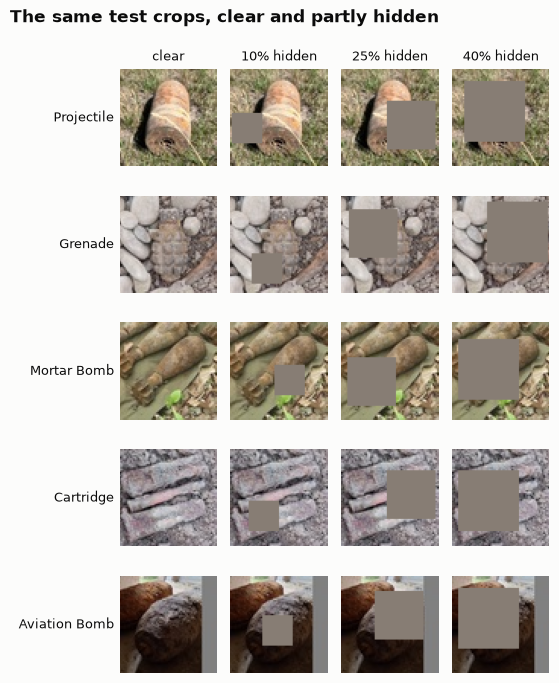

In [11]:
def hide_patches(x, share, rng):
    """Return a copy of crops x with one square patch per crop, covering `share` of it, set to 0 (the average colour)."""
    side = round(x.shape[-1] * math.sqrt(share))
    tops = rng.integers(0, x.shape[-2] - side + 1, len(x))
    lefts = rng.integers(0, x.shape[-1] - side + 1, len(x))
    hidden = x.clone()
    for i, (top, left) in enumerate(zip(tops, lefts)):
        hidden[i, :, top:top + side, left:left + side] = 0.0
    return hidden


patch_rng = np.random.default_rng(SEED)
X_hidden = {share: hide_patches(X["test"], share, patch_rng) for share in HIDDEN_SHARES}


def to_display(x):
    """Undo the standardisation of one crop for display."""
    return (x * channel_std[:, None, None] + channel_mean[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()


fig, axes = plt.subplots(len(CATEGORIES), 1 + len(HIDDEN_SHARES), figsize=(5.6, 7))
for row, category in enumerate(CATEGORIES):
    index = int(np.flatnonzero(Y["test"].numpy() == row)[0])
    versions = [("clear", X["test"][index])] + [(f"{s:.0%} hidden", X_hidden[s][index]) for s in HIDDEN_SHARES]
    for col, (title, crop) in enumerate(versions):
        ax = axes[row, col]
        ax.imshow(to_display(crop))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row == 0:
            ax.set_title(title, fontsize=9, loc="center", fontweight="normal")
    axes[row, 0].set_ylabel(category, rotation=0, ha="right", va="center", fontsize=9, color=INK)
fig.suptitle("The same test crops, clear and partly hidden", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_hidden_patches.png")
plt.show()

## 4. Baseline model

### 4.1 Architecture

A small CNN of the common pattern (Goodfellow et al., 2016, ch. 9): four blocks, each a 3 × 3 convolution, batch normalisation, a ReLU activation and 2 × 2 max pooling, then global average pooling, dropout and one linear layer with five outputs. It is written in full with PyTorch's building blocks (Paszke et al., 2019) and trained from scratch, with no weights learned elsewhere.
- **Convolutions:** each learns local patterns, such as edges, bands and outlines in the first block and shapes built from them deeper in. Small 3 × 3 kernels stacked in depth see a wide area with few weights (Simonyan & Zisserman, 2015). The channels double at each block (32, 64, 128, 256) while pooling halves the image (64, 32, 16, 8, 4 pixels), the usual trade of resolution for richer features.
- **Batch normalisation** rescales each channel's outputs during training, which steadies and speeds up learning (Ioffe & Szegedy, 2015); the convolutions therefore need no bias term.
- **ReLU** keeps positive values and sets negative ones to zero, the standard non-linearity for CNNs.
- **Global average pooling** averages each of the 256 final feature maps to one number (Lin et al., 2014), so the classifier has few weights and does not depend on where in the crop a feature appears.
- **Dropout** sets 30% of those 256 numbers to zero at random during training, which discourages the network from relying on a few features (Srivastava et al., 2014).
- **Output:** five scores (logits), one per category. The loss turns them into probabilities with a softmax, and the highest probability is the model's confidence.

In [12]:
def conv_block(channels_in, channels_out):
    """3 x 3 convolution, batch normalisation, ReLU, then 2 x 2 max pooling (halves height and width)."""
    return nn.Sequential(
        nn.Conv2d(channels_in, channels_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(channels_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class UXOCNN(nn.Module):
    """Four convolution blocks (32, 64, 128, 256 channels), global average pooling, dropout and a linear output layer."""

    def __init__(self, n_classes=len(CATEGORIES), dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 256))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(256, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


model = UXOCNN()
print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
with torch.no_grad():
    print("Output shape for a batch of 2 crops:", tuple(model(X['train'][:2]).shape))

UXOCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )

### 4.2 Training setup

- **Loss:** cross-entropy, the standard loss for choosing one class among several, weighted by category as set out in section 3.3.
- **Optimiser:** Adam (Kingma & Ba, 2015), which adapts the step size of each weight, starting from a learning rate of 0.001, a common default.
- **Learning-rate schedule:** after each epoch the rate is lowered along half a cosine curve, from 0.001 to almost zero in the last epoch (Loshchilov & Hutter, 2017). Large steps early on make fast progress; small steps at the end let the weights settle, so the last epochs change little from one to the next.
- **Batches and epochs:** 64 crops per step, 20 passes over the 10,919 training crops. The number of epochs and the schedule were set from pilot runs of the baseline, judged on the validation crops only: with a constant rate, validation macro-F1 was still rising and jumping from epoch to epoch at epoch 15; with the cosine schedule over 20 epochs it levelled off in the second half of training.
- **Light augmentation, in both models:** each training crop is flipped left to right at random and turned by 0, 90, 180 or 270 degrees, since an object can lie in any direction in a photo. Turns by quarter-turns and flips change no pixel values, only their positions.
- **Model selection:** after each epoch the model is scored on the validation crops, and the weights of the epoch with the best macro-F1 (the average F1 over the five categories, so each counts equally) are kept. The test crops play no part in any choice.
- **Same conditions for both models:** the model's starting weights, the order of the batches and the flips and turns each come from their own seeded random generator, and the second configuration's random erasing draws from a fourth, so the two models see the same crops in the same order with the same flips and turns.

In [13]:
def flip_and_turn(batch, generator):
    """Flip each crop left to right with probability 0.5, then turn it by a random multiple of 90 degrees."""
    flips = torch.rand(len(batch), generator=generator) < 0.5
    batch = torch.where(flips[:, None, None, None], batch.flip(-1), batch)
    turns = torch.randint(0, 4, (len(batch),), generator=generator)
    out = batch.clone()
    for k in (1, 2, 3):
        chosen = turns == k
        if chosen.any():
            out[chosen] = torch.rot90(batch[chosen], k, dims=(-2, -1))
    return out


def predict(model, x, batch=512):
    """Return the model's logits for crops x, in evaluation mode (dropout off, batch-norm statistics fixed)."""
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x[i:i + batch]) for i in range(0, len(x), batch)])


def confusion(y_true, y_pred, k=len(CATEGORIES)):
    """Return the k x k matrix of counts: rows are true categories, columns predicted ones."""
    return np.bincount(np.asarray(y_true) * k + np.asarray(y_pred), minlength=k * k).reshape(k, k)


def scores(y_true, y_pred):
    """Accuracy, macro-F1, and precision, recall and F1 for each category."""
    matrix = confusion(y_true, y_pred)
    true_positive = np.diag(matrix).astype(float)
    precision = np.divide(true_positive, matrix.sum(axis=0), out=np.zeros(len(matrix)), where=matrix.sum(axis=0) > 0)
    recall = np.divide(true_positive, matrix.sum(axis=1), out=np.zeros(len(matrix)), where=matrix.sum(axis=1) > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(matrix)), where=precision + recall > 0)
    return {"accuracy": true_positive.sum() / matrix.sum(), "macro_f1": f1.mean(),
            "precision": precision, "recall": recall, "f1": f1}


def train_model(name, extra_augmentation=None, epochs=EPOCHS):
    """Train a fresh UXOCNN and keep the weights of the epoch with the best validation macro-F1.

    `extra_augmentation`, if given, is applied to each batch after the flips and turns; it is the one
    thing that differs between the two configurations. Returns the model, its history and the best epoch.
    """
    torch.manual_seed(SEED)  # same starting weights for both models
    model = UXOCNN()
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    order_generator = torch.Generator().manual_seed(SEED)
    turn_generator = torch.Generator().manual_seed(SEED + 1)
    erase_generator = torch.Generator().manual_seed(SEED + 2)
    n = len(X["train"])
    history, best = [], (-1.0, 0, None)
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        rate = optimiser.param_groups[0]["lr"]  # the learning rate used in this epoch
        order = torch.randperm(n, generator=order_generator)
        running = 0.0
        for start in range(0, n, BATCH):
            batch = order[start:start + BATCH]
            x = flip_and_turn(X["train"][batch], turn_generator)
            if extra_augmentation is not None:
                x = extra_augmentation(x, erase_generator)
            optimiser.zero_grad()
            loss = loss_fn(model(x), Y["train"][batch])
            loss.backward()
            optimiser.step()
            running += loss.item() * len(batch)
        schedule.step()
        logits = predict(model, X["valid"])
        valid = scores(Y["valid"].numpy(), logits.argmax(1).numpy())
        history.append({"epoch": epoch, "learning rate": rate, "train loss": running / n,
                        "validation loss": loss_fn(logits, Y["valid"]).item(),
                        "validation accuracy": valid["accuracy"], "validation macro-F1": valid["macro_f1"]})
        if valid["macro_f1"] > best[0]:
            best = (valid["macro_f1"], epoch, copy.deepcopy(model.state_dict()))
    model.load_state_dict(best[2])
    print(f"{name}: {epochs} epochs in {time.perf_counter() - started:.0f} s")
    print(f"{name}: best validation macro-F1 {best[0]:.3f} at epoch {best[1]}; those weights are kept.")
    return model, pd.DataFrame(history).set_index("epoch"), best[1]

## 5. Train the baseline

Training the baseline for 20 epochs. The table shows, for each epoch, the learning rate used, the training loss (averaged over the epoch, with augmentation and dropout on), and the loss, accuracy and macro-F1 on the validation crops after the epoch.

In [14]:
HISTORY_DECIMALS = {"learning rate": 6, "train loss": 3, "validation loss": 3, "validation accuracy": 3, "validation macro-F1": 3}
baseline, baseline_history, baseline_epoch = train_model("Baseline")
print()
print(baseline_history.round(HISTORY_DECIMALS).to_string())

Baseline: 20 epochs in 868 s
Baseline: best validation macro-F1 0.521 at epoch 19; those weights are kept.

       learning rate  train loss  validation loss  validation accuracy  validation macro-F1
epoch                                                                                      
1           0.001000       1.278            1.469                0.514                0.382
2           0.000994       1.105            1.379                0.444                0.374
3           0.000976       1.030            1.413                0.508                0.404
4           0.000946       0.950            1.342                0.473                0.408
5           0.000905       0.905            1.323                0.523                0.425
6           0.000854       0.857            1.240                0.517                0.447
7           0.000794       0.828            1.322                0.526                0.441
8           0.000727       0.801            1.237               

**Baseline training.** The training loss falls steadily, from 1.278 in the first epoch to 0.541 in the last. Validation macro-F1 rises from 0.382 to 0.511 by epoch 11 and then holds between 0.48 and 0.52 as the learning rate shrinks; the best epoch, 19 (0.521), is kept. The validation loss jumps from epoch to epoch and ends at 1.164, about twice the training loss: the network fits the training crops much better than crops from new photos, a sign that some of what it learns belongs to the training scenes rather than to the objects. The jumps in validation macro-F1 settle in the last epochs, when the learning rate is small, which is what the schedule is for.